# AGENT02 — Q-learning so với rule-based

Notebook kiểm mô hình, cập nhật Q, policy đóng băng, oracle và dữ liệu thí nghiệm A–E. Kết quả đầy đủ từ 36 lượt training của bản mở rộng đã được chạy bằng script và lưu trong ket_qua/assignment. Notebook mặc định **đọc các artifact này và thực thi những phép kiểm minh họa**, không chạy lại ngầm 3.6 triệu bước.

Bật RUN_FULL_EXPERIMENT=True nếu muốn train lại toàn bộ; thao tác đó ghi lại thư mục kết quả và nên chạy lại build_documents.py sau cùng. Báo cáo PDF trả lời đầy đủ 10 câu hỏi.

In [1]:
from pathlib import Path
import sys, json, csv, inspect, subprocess
import numpy as np
from IPython.display import display, Image, HTML
ROOT = Path.cwd()
if not (ROOT / 'code_agent/tutorial').exists():
    ROOT = ROOT.parent
assert (ROOT / 'code_agent/tutorial/mas_system.py').exists(), 'Open notebook from project root'
sys.path[:0] = [str(ROOT / 'code_agent/tutorial'), str(ROOT / 'code_agent/assignment')]

def show_csv(path, limit=30):
    rows = list(csv.DictReader(path.open(encoding='utf-8')))
    import html
    if not rows: return
    columns = list(rows[0])
    head = '<tr>' + ''.join('<th>'+html.escape(c)+'</th>' for c in columns) + '</tr>'
    body = ''.join('<tr>'+''.join('<td>'+html.escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows[:limit])
    display(HTML('<table>'+head+body+'</table>'))
    print(f'{path.name}: {len(rows)} rows; showing {min(limit,len(rows))}')
print('Working directory:', ROOT)


Working directory: <PROJECT_DIR>


## 1. Cấu hình và môi trường

In [2]:
from agent02_experiment import *
from dataclasses import asdict, replace
print(json.dumps(asdict(Config()),indent=2))
env=Environment(seed=42)
print('Initial:',env.reset())
print('Joint step:',env.step([0,1]))

{
  "episodes": 5000,
  "horizon": 20,
  "evaluation_episodes": 500,
  "alpha": 0.1,
  "gamma": 0.9,
  "epsilon_start": 0.2,
  "epsilon_min": 0.02,
  "epsilon_decay": 0.995,
  "price": 10.0,
  "cost": 5.0,
  "discount": 0.2
}
Initial: [(0, 0), (0, 0)]
Joint step: ([(1, 1), (1, 0)], [10.0, 6.0], {'sales': [2, 2], 'conversion': [0.19999999999999998, 0.44999999999999996], 'customers': 10})


## 2. Margin và bảng kỳ vọng
Bảng này là phép tính lý thuyết, khác với sampled reward.

In [3]:
cfg=Config()
for d in [0,1]:
    for b in [0,1]:
        print('demand=',d,'opponent=',b,'no discount=',expected_profit(cfg,d,0,b),'discount=',expected_profit(cfg,d,1,b))
print('Margins:',cfg.price-cfg.cost,cfg.price*(1-cfg.discount)-cfg.cost)

demand= 0 opponent= 0 no discount= 15.0 discount= 13.5
demand= 0 opponent= 1 no discount= 9.999999999999998 discount= 10.5
demand= 1 opponent= 0 no discount= 55.0 discount= 42.00000000000001
demand= 1 opponent= 1 no discount= 45.00000000000001 discount= 36.00000000000001
Margins: 5.0 3.0


## 3. Q-learning update tính tay
Nonterminal cho kết quả 4.65; terminal không bootstrap.

In [4]:
agent=QLearningAgent()
agent.q[0,0,0]=4;agent.q[1,1]=[5,2]
agent.learn((0,0),0,6,(1,1))
print('Updated Q=',agent.q[0,0,0])
assert np.isclose(agent.q[0,0,0],4.65)
print(inspect.getsource(QLearningAgent.learn))

Updated Q= 4.65
    def learn(self,s,a,r,ns,terminal=False):
        target = r if terminal else r+self.cfg.gamma*float(max(self.q[ns]))
        idx=(*s,a); self.q[idx] += self.cfg.alpha*(target-self.q[idx])



## 4. Chạy training ngắn để kiểm tái lập
200 episode chỉ là smoke demonstration, không thay thế 5.000 episode của bảng kết quả chính.

In [5]:
small=replace(cfg,episodes=200)
agent,_,history,counts=train(small,42)
print('Episodes:',len(history),'training action counts:',counts.tolist())
print('First:',history[0]);print('Last:',history[-1])
q=agent.q.copy();measured,_=evaluate(cfg,agent.q,seed=500042)
assert np.array_equal(q,agent.q)
print('Frozen smoke evaluation:',measured)

Episodes: 200 training action counts: [[2370, 1630], [3210, 790]]
First: {'episode': 1, 'rl_total': 583.0, 'opponent_total': 577.0, 'rl_mean': 29.15, 'opponent_mean': 28.85, 'epsilon': 0.2}
Last: {'episode': 200, 'rl_total': 685.0, 'opponent_total': 615.0, 'rl_mean': 34.25, 'opponent_mean': 30.75, 'epsilon': 0.07376036617611398}
Frozen smoke evaluation: [{'agent': 'focal', 'total_reward': 348295.0, 'mean_reward': 34.8295, 'episode_sd': 4.9890214893144815, 'no_discount': 10000, 'discount': 0, 'discount_rate': 0.0}, {'agent': 'opponent', 'total_reward': 346340.0, 'mean_reward': 34.634, 'episode_sd': 4.819387616076131, 'no_discount': 10000, 'discount': 0, 'discount_rate': 0.0}]


## 5. Đọc kết quả baseline 42 đã train đủ

In [6]:
summary=json.loads((ROOT/'ket_qua/assignment/summary.json').read_text())
print('Environment:',summary['python'],summary['numpy'])
print('Q:',np.array(summary['baseline']['q']))
show_csv(ROOT/'ket_qua/assignment/baseline_42_summary.csv')

Environment: 3.9.6 1.26.4
Q: [[[184.21286701 199.4490361 ]
  [221.95604665 181.66800997]]

 [[227.27976083 235.19751263]
  [197.47170098 218.16258916]]]
baseline_42_summary.csv: 2 rows; showing 2


agent,total_reward,mean_reward,episode_sd,no_discount,discount,discount_rate
focal,255591.0,25.5591,3.122348524848122,1849,8151,0.8151
opponent,246856.0,24.6856,3.4513745976388095,6147,3853,0.3853


## 6. Đối chiếu code gốc
Seed giống số học nhưng stream khác. Cả hai kết quả được lưu riêng.

In [7]:
show_csv(ROOT/'ket_qua/assignment/reference_original_42_summary.csv')

reference_original_42_summary.csv: 2 rows; showing 2


agent,total_reward,mean_reward_per_step,no_discount_actions,discount_actions,discount_action_rate
RL,351275.0,35.1275,10000,0,0.0
Rule-based,349685.0,34.9685,10000,0,0.0


## 7. Alpha và epsilon trên năm seed

In [8]:
show_csv(ROOT/'ket_qua/assignment/aggregate.csv')
show_csv(ROOT/'ket_qua/assignment/configurations.csv')

aggregate.csv: 5 rows; showing 5
configurations.csv: 25 rows; showing 25


configuration,mean,sd,ci95_half_t4,discount_rate,train_mean,first500,last500
baseline,34.0997,1.367797077420477,1.698072118167347,0.16164,33.651332,32.859480000000005,33.671839999999996
alpha_001,33.64838,2.128563830849336,2.642537370909741,0.19914,32.094395999999996,30.992380000000004,33.75410000000001
alpha_050,31.953279999999996,4.161269864716779,5.1660706475346245,0.38083999999999996,31.851973999999995,30.858179999999997,31.89064
epsilon_005,33.3973,1.6126064274955623,2.001994343540972,0.27902,32.945848,32.122,33.01536
epsilon_030,31.429999999999996,3.927223500133396,4.875510291310602,0.33876,30.882198,30.897100000000005,30.688660000000006


configuration,seed,agent,total_reward,mean_reward,episode_sd,no_discount,discount,discount_rate,opponent_mean,train_mean,train_first_500,train_last_500,train_discount_rate
baseline,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0,35.245999999999995,33.69638,32.7194,34.1653,0.15682
baseline,22,focal,325267.0,32.5267,5.325414743885098,5930,4070,0.407,30.4536,33.48831,32.4667,33.8053,0.16321
baseline,33,focal,326863.0,32.6863,5.225526726478229,5988,4012,0.4012,30.618299999999998,33.65692,32.8143,33.663599999999995,0.15228
baseline,44,focal,349350.0,34.935,4.8014980753443055,10000,0,0.0,35.101,33.69092,33.3355,33.531400000000005,0.1513
baseline,55,focal,351680.0,35.168,5.067853814443461,10000,0,0.0,35.176,33.72413,32.9615,33.193599999999996,0.15371
alpha_001,11,focal,308131.0,30.8131,4.58451294117659,5021,4979,0.4979,29.109199999999998,27.097180000000005,26.0503,30.5618,0.72588
alpha_001,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0,35.0565,32.21478,31.4475,34.557900000000004,0.42105
alpha_001,33,focal,352710.0,35.271,5.1331283847209646,10000,0,0.0,35.0755,31.700440000000004,28.3465,34.7505,0.23399
alpha_001,44,focal,318988.0,31.8988,4.923327825134895,5022,4978,0.4978,29.523899999999998,34.6586,34.7697,34.260200000000005,0.03741
alpha_001,55,focal,351680.0,35.168,5.067853814443461,10000,0,0.0,35.176,34.800979999999996,34.347899999999996,34.640100000000004,0.02141


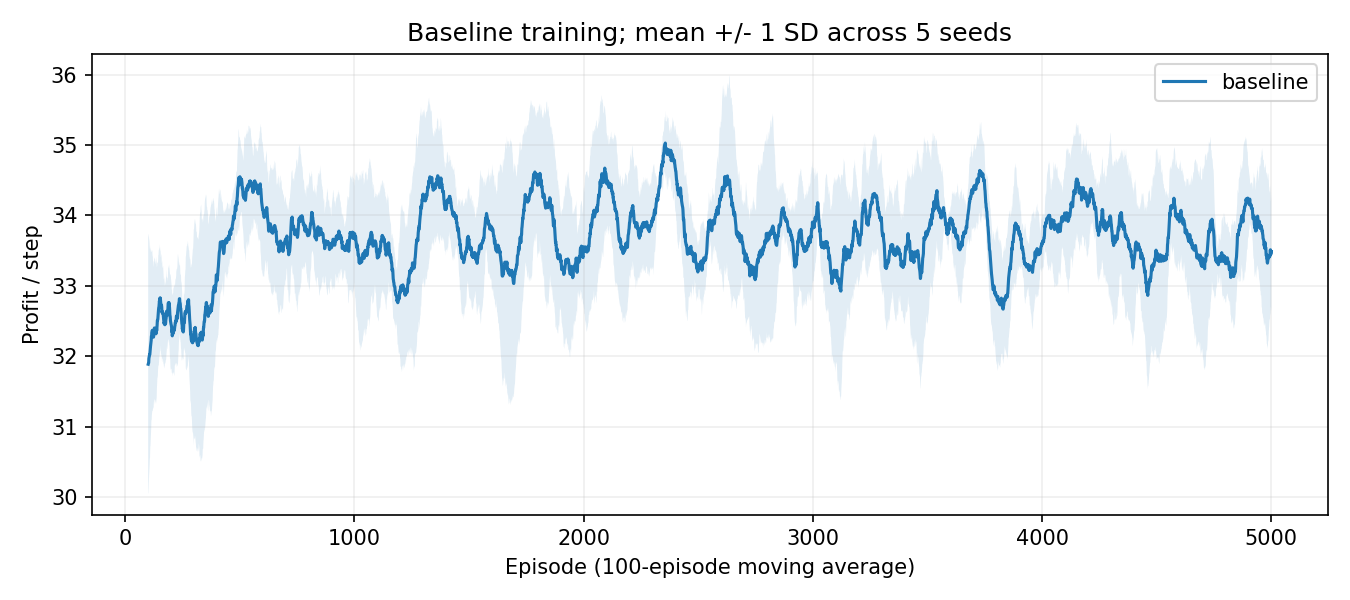

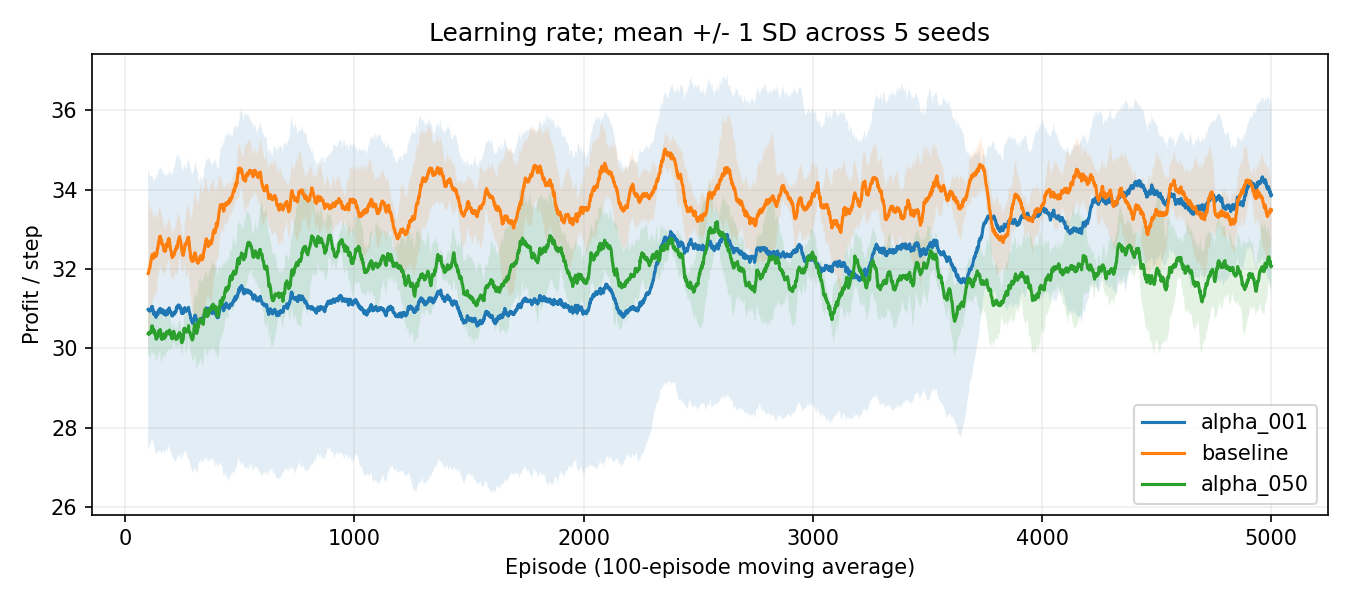

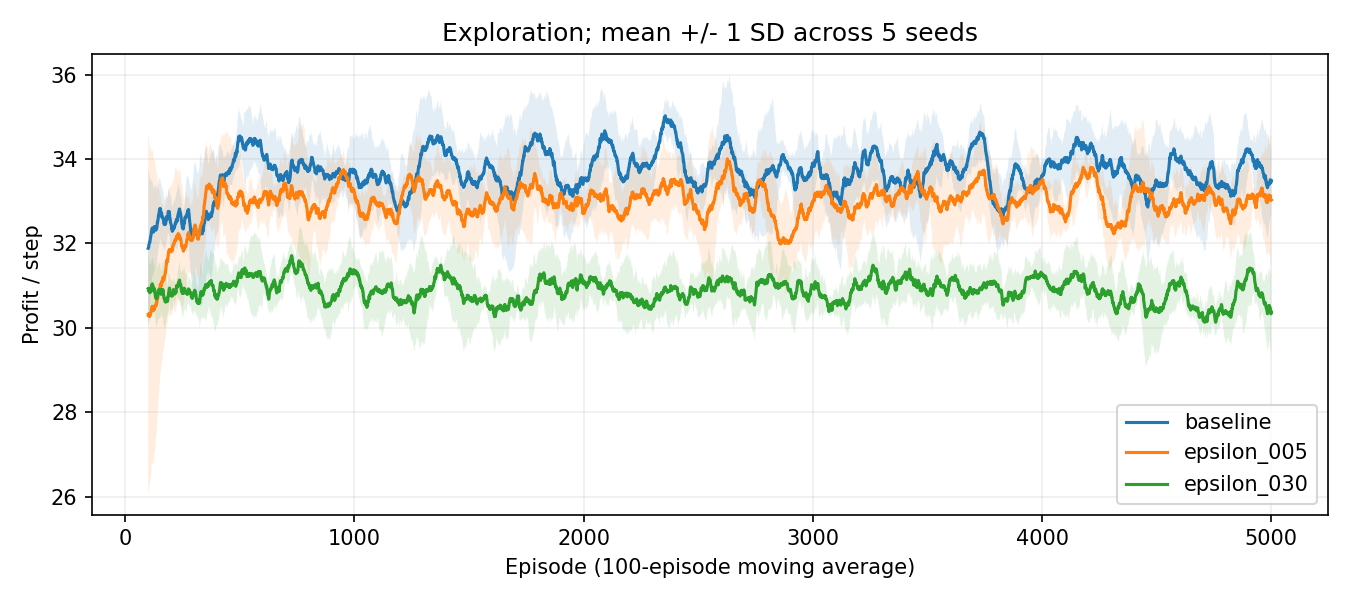

In [9]:
display(Image(filename=str(ROOT/'ket_qua/assignment/learning_curve.png')))
display(Image(filename=str(ROOT/'ket_qua/assignment/learning_rates.png')))
display(Image(filename=str(ROOT/'ket_qua/assignment/exploration.png')))

## 8. So sánh công bằng
Mọi focal policy cùng fixed rule opponent, cùng demand và uniform sales tape.

fair_comparison.csv: 25 rows; showing 25


policy,seed,agent,total_reward,mean_reward,episode_sd,no_discount,discount,discount_rate
RL,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
Rule,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
Never,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
Always,11,focal,250692.0,25.069200000000002,3.000704887128902,0,10000,1.0
DP,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
RL,22,focal,325267.0,32.5267,5.325414743885098,5930,4070,0.407
Rule,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0
Never,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0
Always,22,focal,249519.0,24.951900000000002,3.0526035062439187,0,10000,1.0
DP,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0


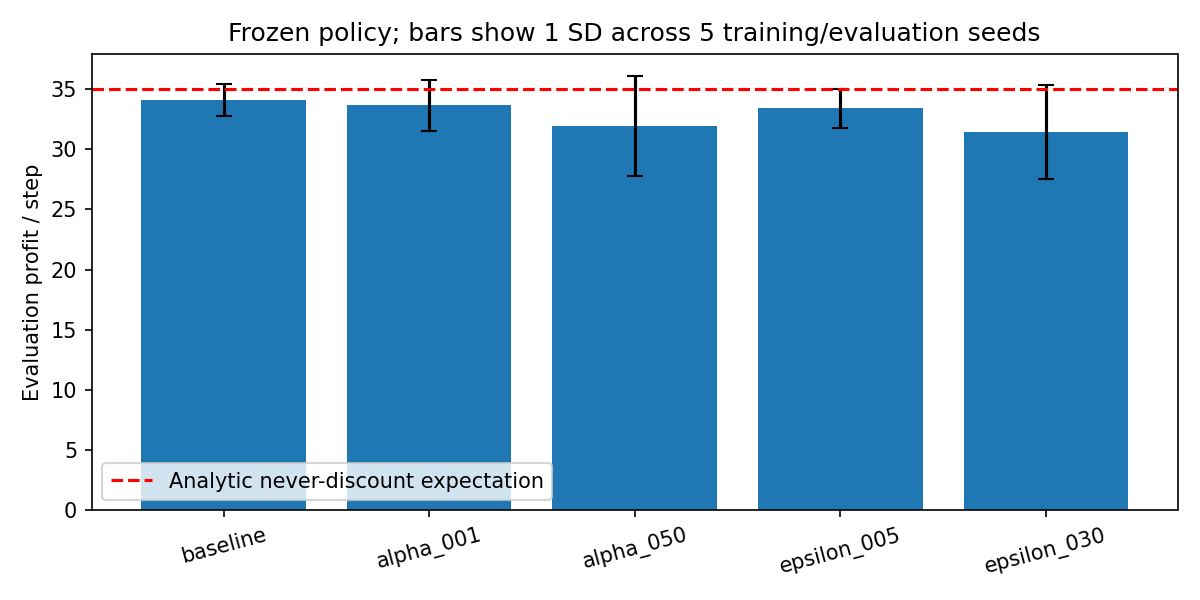

In [10]:
show_csv(ROOT/'ket_qua/assignment/fair_comparison.csv')
display(Image(filename=str(ROOT/'ket_qua/assignment/evaluation.png')))

## 9. Chứng minh thiếu state bằng hai lịch sử
Cùng observation (high, opponent previous 0), nhưng own previous action khác làm opponent current action khác.

In [11]:
for own_previous in [0,1]:
    opponent_current=1*own_previous
    print('own_previous=',own_previous,'observed=(1,0)','opponent_current=',opponent_current,'profit_no_discount=',expected_profit(cfg,1,0,opponent_current))

own_previous= 0 observed=(1,0) opponent_current= 0 profit_no_discount= 55.0
own_previous= 1 observed=(1,0) opponent_current= 1 profit_no_discount= 45.00000000000001


## 10. DP hữu hạn chân trời với đầy đủ state

In [12]:
policy,values=exact_best_response(cfg)
print('Policy shape:',policy.shape,'all choose no discount:',bool((policy==0).all()))
assert (policy==0).all()
dp_result,_=evaluate(cfg,policy,seed=800011)
print(dp_result)
print(inspect.getsource(exact_best_response))

Policy shape: (20, 2, 2, 2) all choose no discount: True
[{'agent': 'focal', 'total_reward': 351825.0, 'mean_reward': 35.1825, 'episode_sd': 5.183053814469552, 'no_discount': 10000, 'discount': 0, 'discount_rate': 0.0}, {'agent': 'opponent', 'total_reward': 352460.0, 'mean_reward': 35.245999999999995, 'episode_sd': 5.065303406232878, 'no_discount': 10000, 'discount': 0, 'discount_rate': 0.0}]
def exact_best_response(cfg):
    """Finite-horizon DP on full Markov state (d, own_prev, opponent_prev).
    The fixed opponent's current action is d * own_prev; current actions simultaneous.
    """
    V=np.zeros((cfg.horizon+1,2,2,2)); policy=np.zeros((cfg.horizon,2,2,2),dtype=int)
    for t in range(cfg.horizon-1,-1,-1):
        for d in (0,1):
            for own in (0,1):
                for opp in (0,1):
                    b=d*own
                    values=[expected_profit(cfg,d,a,b)+cfg.gamma*np.mean(V[t+1,:,a,b]) for a in (0,1)]
                    policy[t,d,own,opp]=int(np.argmax(val

## 11. Exact policy evaluation bằng occupancy
Phép tính không lấy mẫu, tách khác biệt policy khỏi noise evaluation.

In [13]:
from analyze_exact import exact_mean
exact,steps=exact_mean(cfg,np.array(summary['baseline']['q']))
print('Baseline42 exact mean:',exact)
show_csv(ROOT/'ket_qua/assignment/exact_policy_values.csv')

Baseline42 exact mean: 25.697999954223633
exact_policy_values.csv: 25 rows; showing 25


configuration,seed,exact_mean,sampled_mean,sample_error,policy_bits
baseline,11,35.0,35.1825,0.18249999999999744,0000
baseline,22,32.44799995422363,32.5267,0.07870004577636536,1000
baseline,33,32.44799995422363,32.6863,0.23830004577636998,1000
baseline,44,35.0,34.935,-0.06499999999999773,0001
baseline,55,35.0,35.168,0.16799999999999926,0000
alpha_001,11,30.58125,30.8131,0.2318499999999979,1001
alpha_001,22,35.0,35.091,0.09100000000000108,0100
alpha_001,33,35.0,35.271,0.2710000000000008,0100
alpha_001,44,31.875,31.8988,0.023800000000001376,1100
alpha_001,55,35.0,35.168,0.16799999999999926,0000


## 12. Robustness discount 40% và self-play

In [14]:
show_csv(ROOT/'ket_qua/assignment/robustness_discount40.csv')
show_csv(ROOT/'ket_qua/assignment/selfplay_summary.csv')

robustness_discount40.csv: 20 rows; showing 20
selfplay_summary.csv: 10 rows; showing 10


policy,seed,agent,total_reward,mean_reward,episode_sd,no_discount,discount,discount_rate
frozen_RL,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
retrained_RL,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
Rule,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
DP,11,focal,351825.0,35.1825,5.183053814469552,10000,0,0.0
frozen_RL,22,focal,288619.0,28.861900000000002,6.13258187968347,5930,4070,0.407
retrained_RL,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0
Rule,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0
DP,22,focal,350910.0,35.091,5.281762303062502,10000,0,0.0
frozen_RL,33,focal,290601.0,29.0601,5.972483076426118,5988,4012,0.4012
retrained_RL,33,focal,276282.0,27.6282,6.218300352874338,5064,4936,0.4936


seed,learner,agent,total_reward,mean_reward,episode_sd,no_discount,discount,discount_rate
11,0,focal,305514.0,30.5514,5.14770879631933,8036,1964,0.1964
11,1,opponent,325935.0,32.5935,4.94747286252799,5979,4021,0.4021
22,0,focal,350545.0,35.054500000000004,4.706187539006984,10000,0,0.0
22,1,opponent,351300.0,35.13,4.576569673888939,10000,0,0.0
33,0,focal,353565.0,35.3565,4.874890960190545,10000,0,0.0
33,1,opponent,354800.0,35.480000000000004,4.879700087699221,10000,0,0.0
44,0,focal,348160.0,34.816,4.864382636766329,10000,0,0.0
44,1,opponent,347835.0,34.7835,5.005283055625712,10000,0,0.0
55,0,focal,348630.0,34.863,5.10822071152719,10000,0,0.0
55,1,opponent,350500.0,35.05,5.125064152294121,10000,0,0.0


## 13. Kiểm thử và tùy chọn chạy lại đầy đủ

In [15]:
completed=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'code_agent/assignment'),'-p','test_*.py'],cwd=ROOT,capture_output=True,text=True)
print(completed.stdout+completed.stderr)
assert completed.returncode==0
RUN_FULL_EXPERIMENT=False
if RUN_FULL_EXPERIMENT:
    run(ROOT/'ket_qua/assignment',episodes=5000)
else:
    print('Full experiment already measured; flag False preserves supplied artifacts')

............
----------------------------------------------------------------------
Ran 12 tests in 0.097s

OK

Full experiment already measured; flag False preserves supplied artifacts


## 14. Kết luận
Baseline RL chưa vượt rule/DP trong mô hình này. Một run có thể rất khác nhóm seed; ảnh hưởng state thiếu và target terminal cần được phân tích. Reward training không đồng nhất frozen performance. Dữ liệu mô phỏng không tạo bằng chứng lợi ích kinh doanh ngoài thực tế.